# 03 — Diagnostics

**Question:** where does v1 (MAE 38.8 kW) fail?
Setup re-runs `02`'s pipeline in 12 lines. All new work below is diagnostics.

## Setup — reproduce 02's pipeline (same as 02, no new logic)

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

import solarops.pipeline
from solarops.pipeline import (
  load_raw, align_15m, split_time, impute_features, evaluate
)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data/raw/pvdaq/2023-solar-data-prize/system-2107"

raw = load_raw(DATA_DIR)
df = align_15m(raw)
train, test = split_time(df, "2022-07-01")
X_train, X_test, y_train, y_test = impute_features(train, test)

v1 = LinearRegression().fit(X_train, y_train)
print("v1:", evaluate(v1, X_test, y_test, "v1"))

v1: {'model': 'v1', 'MAE': 38.75508100931854, 'RMSE': 66.6306598077406, 'R2': 0.9171105283246033}


## Build the residual table

`residual = actual − predicted`.\
Positive = model under-predicted.\
Negative = **system underperformed expectations**
(the exact case SolarOps exists to flag).

In [10]:
v1_pred = v1.predict(X_test)

resid = pd.DataFrame({
  "measured_on": test["measured_on"].values,
  "actual": y_test,
  "predicted": v1_pred,
  "residual": y_test - v1_pred
})
resid["hour"]  = resid["measured_on"].dt.hour
resid["month"] = resid["measured_on"].dt.month

print("residual mean :", round(resid["residual"].mean(), 2), "kW (bias)")
print("residual std :", round(resid["residual"].std(), 2), "kW")
print("|err| > 100kW :", f'{(resid["residual"].abs() > 100).mean()*100:.1f}% of test rows')


residual mean : 0.6 kW (bias)
residual std : 66.63 kW
|err| > 100kW : 13.2% of test rows


## Plot 1 + 2 — residual vs hour, residual vs POA
Boxes summarise each hour's / each irradiance bin's residual spread.
Flat median line = stable. Sloped = the model misses systematically in that regime.

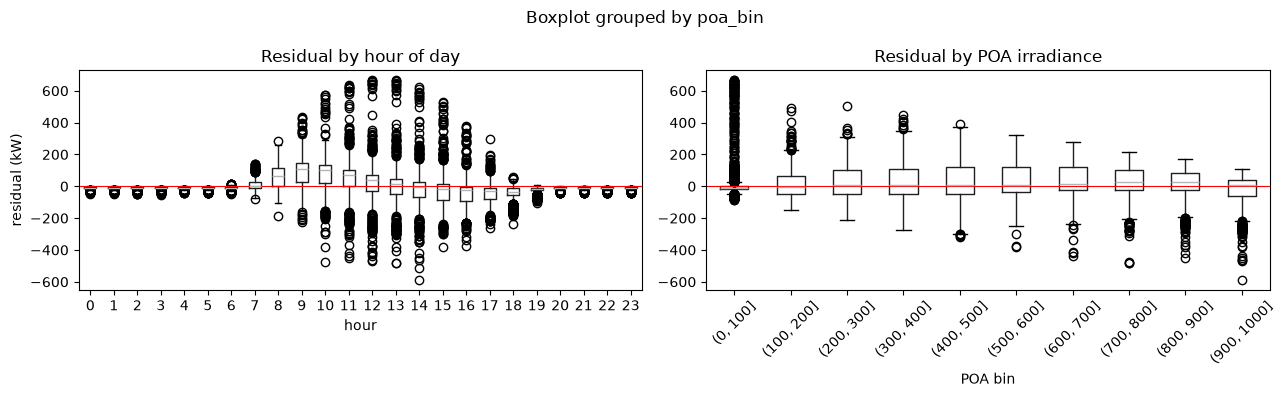

In [12]:
from solarops.pipeline import IRRADIANCE_COL

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Hour-of-day
resid.boxplot(column="residual", by="hour", ax=ax[0], grid=False)
ax[0].axhline(0, color="red", lw=0.8)
ax[0].set_title("Residual by hour of day"); ax[0].set_xlabel("hour"); ax[0].set_ylabel("residual (kW)")
plt.suptitle("")

# POA bin
resid["poa"] = X_test[IRRADIANCE_COL].values
resid["poa_bin"] = pd.cut(resid["poa"], bins=np.arange(0, 1100, 100))
resid.boxplot(column="residual", by="poa_bin", ax=ax[1], grid=False, rot=45)
ax[1].axhline(0, color="red", lw=0.8)
ax[1].set_title("Residual by POA irradiance"); ax[1].set_xlabel("POA bin"); ax[1].set_ylabel("")

plt.tight_layout(); plt.show()

## Plot 3 + 4 — residual by month, residual distribution

- **By month:** is one season systematically worse? (test window Jul 2022 – Oct 2023 misses spring.)
- **Distribution:** symmetric (pure noise) vs skewed (structured error) vs heavy tails (a few huge misses).

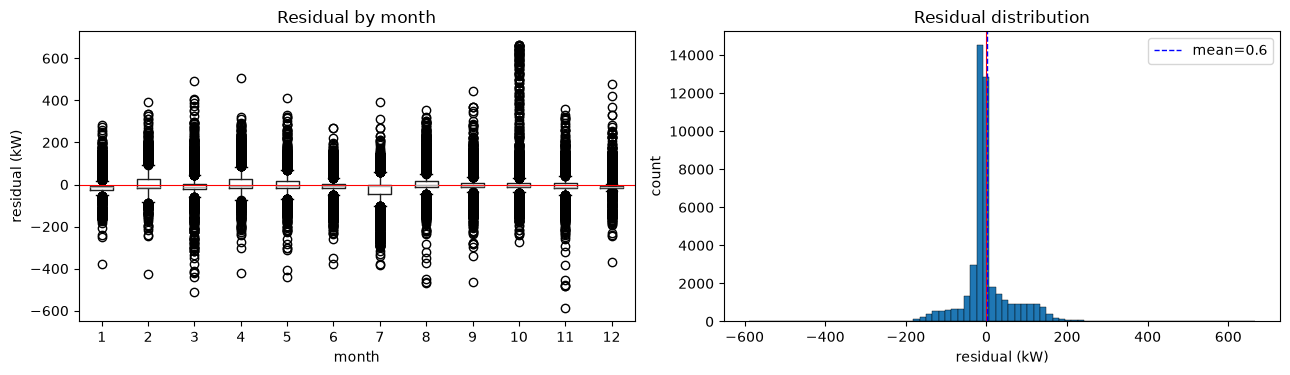

skew: 1.33
kurtosis: 12.63


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# By month
resid.boxplot(column="residual", by="month", ax=ax[0], grid=False)
ax[0].axhline(0, color="red", lw=0.8)
ax[0].set_title("Residual by month"); ax[0].set_xlabel("month"); ax[0].set_ylabel("residual (kW)")
plt.suptitle("")

# Distribution
ax[1].hist(resid["residual"], bins=80, edgecolor="black", lw=0.3)
ax[1].axvline(0, color="red", lw=0.8)
ax[1].axvline(resid["residual"].mean(), color="blue", lw=1, ls="--", label=f"mean={resid['residual'].mean():.1f}")
ax[1].set_title("Residual distribution"); ax[1].set_xlabel("residual (kW)"); ax[1].set_ylabel("count")
ax[1].legend()

plt.tight_layout(); plt.show()

print("skew:", round(resid["residual"].skew(), 2))
print("kurtosis:", round(resid["residual"].kurt(), 2))

## What v1 fails on

_Numbers:_
- MAE 38.8 kW · RMSE 66.6 kW · 13.2% of rows off by >100 kW · bias +0.6 kW (unbiased).
- RMSE / MAE = 1.7 → heavy tails, structured error, not pure noise.

_Where (from plots):_
- By hour: median ≈ 0 all day, but **±600 kW spread during hours 9–16**. Night hours are just numerical noise.
- By POA: **systematic tilt** — under-predicts at low POA (< 400), over-predicts at high POA (> 600). Peak error near 900–1000 POA.
- By month: no month has systematic bias (median ≈ 0 all months).
  October has one extreme +700 kW outlier (worth checking later).
- Distribution: sharp spike near 0 = night rows (actual 0, predicted ~17).
  Right-skewed (+1.33): the biggest misses are under-predictions at low POA.
  Heavy tails (kurtosis 12.6): a few rows off by 500–700 kW drive RMSE up.

_Interpretation:_
Linear model assumes "power ∝ irradiance". Reality is curved:
- Low light → panels convert a **higher fraction** (model too pessimistic).
- High light → **heat derating + inverter clipping** (model too optimistic).

_Decision for notebook 04:_
1. Non-linear model (LightGBM) — captures the curve linear misses.
2. Add features: hour_of_day, month, and maybe `poa * temperature` interaction.
3. Target metrics: flatten the POA tilt AND reduce the right-skew tail.
   RMSE closer to MAE = fewer 100+ kW misses.